In [2]:
!pip install numpy pandas matplotlib torch scikit-learn

# GCN from scratch: fraud detection on a synthetic graph

This notebook implements a two-layer Graph Convolutional Network (GCN) from raw PyTorch
tensor operations (no `torch_geometric`, no `dgl`, no ready-made GNN layers), trains it on
a synthetic fraud-detection graph, verifies correctness, and measures how much the model
actually relies on graph structure.

**Run All** runs the entire pipeline: data loading, model definitions, training, the two
correctness checks, the GCN-vs-MLP comparison (averaged over 5 seeds), and the edge-corruption
ablation sweep.



In [3]:
import os
import copy
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

pd.set_option("display.float_format", lambda x: f"{x:.3f}")


## 1. Config

All the knobs we discussed live here. Change a value and re-run the notebook.

In [4]:
CONFIG = dict(
    hidden_dim=16,
    lr=0.01,
    weight_decay=5e-4,
    dropout=0.5,
    max_epochs=300,
    patience=20,              # early stopping: epochs to wait for val loss improvement
    use_class_weights=True,   # weight the minority (fraud) class in the loss
    seeds=[0, 1, 2, 3, 4],    # for seed-averaged comparisons
    corruption_levels=[0.0, 0.25, 0.5, 0.75, 1.0],  # fraction of edges randomized
    train_frac=0.6,
    val_frac=0.2,             # remainder (0.2) is test
    split_seed=0,
)


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


## 2. Load dataset

In [6]:
candidates = ["dataset.npz", "/kaggle/input/datasets/naodabebenegussie/gnn-training/dataset.npz"]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), candidates[0])

data = np.load(DATA_PATH)
X_raw = data["features"].astype(np.float32)   # (N, 3): amount, account_age, velocity
y_all = data["labels"].astype(np.int64)        # (N,): 0 = legit, 1 = fraud
edges = data["edges"].astype(np.int64)         # (E, 2)
N = X_raw.shape[0]

print(f"Loaded {DATA_PATH}")
print(f"{N} nodes, {len(edges)} edges, {y_all.sum()} fraud / {N - y_all.sum()} legit")


Loaded /kaggle/input/datasets/naodabebenegussie/gnn-training/dataset.npz
250 nodes, 636 edges, 75 fraud / 175 legit


## 3. Train / validation / test split

Stratified split on labels so each split keeps roughly the same fraud/legit ratio. The split
only selects which nodes' **labels** are used for training/validation/testing — every node's
features and edges stay visible to the model for message passing (this is standard transductive
node classification). Target labels are never used as input features.


In [7]:
idx_all = np.arange(N)
idx_train, idx_temp = train_test_split(
    idx_all, test_size=(1 - CONFIG["train_frac"]), stratify=y_all, random_state=CONFIG["split_seed"]
)
val_rel = CONFIG["val_frac"] / (1 - CONFIG["train_frac"])
idx_val, idx_test = train_test_split(
    idx_temp, test_size=(1 - val_rel), stratify=y_all[idx_temp], random_state=CONFIG["split_seed"]
)

print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}")
for name, idx in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    print(f"  {name}: {y_all[idx].sum()} fraud / {len(idx) - y_all[idx].sum()} legit")

# Standardize features using TRAIN statistics only, then apply to all nodes (no leakage).
feat_mean = X_raw[idx_train].mean(axis=0)
feat_std = X_raw[idx_train].std(axis=0) + 1e-8
X = (X_raw - feat_mean) / feat_std


train=150  val=50  test=50
  train: 45 fraud / 105 legit
  val: 15 fraud / 35 legit
  test: 15 fraud / 35 legit


## 4. Build the normalized adjacency matrix

This is the manual implementation of self-loops + symmetric degree normalization:

$$\hat{A} = A + I \qquad \tilde{A} = D^{-1/2} \hat{A} D^{-1/2}$$

`build_adjacency` turns the edge list into a dense N x N matrix. `normalize_adjacency` adds
self-loops and applies symmetric normalization. Both are pure NumPy so they're easy to
unit-check independently of PyTorch.


In [8]:
def build_adjacency(edge_list, n):
    A = np.zeros((n, n), dtype=np.float32)
    for s, t in edge_list:
        A[s, t] = 1.0
        A[t, s] = 1.0
    return A


def normalize_adjacency(A):
    n = A.shape[0]
    A_hat = A + np.eye(n, dtype=np.float32)      # add self-loops
    deg = A_hat.sum(axis=1)                       # degree counting the self-loop
    deg_inv_sqrt = np.zeros_like(deg)
    nonzero = deg > 0
    deg_inv_sqrt[nonzero] = np.power(deg[nonzero], -0.5)
    D_inv_sqrt = np.diag(deg_inv_sqrt)
    return (D_inv_sqrt @ A_hat @ D_inv_sqrt).astype(np.float32)


A = build_adjacency(edges, N)
A_norm = normalize_adjacency(A)

assert np.allclose(A_norm, A_norm.T), "normalized adjacency should be symmetric"
print("Normalized adjacency built. Symmetric:", np.allclose(A_norm, A_norm.T))

X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y_all, dtype=torch.long)
A_norm_t = torch.tensor(A_norm, dtype=torch.float32)
idx_train_t = torch.tensor(idx_train, dtype=torch.long)
idx_val_t = torch.tensor(idx_val, dtype=torch.long)
idx_test_t = torch.tensor(idx_test, dtype=torch.long)

class_counts = np.bincount(y_all[idx_train])
class_weights = (
    torch.tensor(len(idx_train) / (2.0 * class_counts), dtype=torch.float32)
    if CONFIG["use_class_weights"] else None
)
print("Class weights (legit, fraud):", class_weights)


Normalized adjacency built. Symmetric: True
Class weights (legit, fraud): tensor([0.7143, 1.6667])


## 5. Model definitions (from scratch)

`GCNLayer` implements one propagation step directly as tensor operations:
`H' = A_norm @ (H @ W) + b` — the linear transform `H @ W` and the neighborhood aggregation
`A_norm @ (...)` are both explicit, no library GNN layer is used. `GCN` stacks two of these
layers with a ReLU and dropout in between. `MLP` is the same hidden-dim baseline but with
**no** access to `A_norm` at all (it ignores it), so the comparison isolates the effect of
graph structure rather than the effect of having one more linear layer.


In [9]:
class GCNLayer(nn.Module):
    """One GCN propagation step: H' = A_norm @ (H @ W) + b."""

    def __init__(self, in_dim, out_dim, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_dim, out_dim))
        self.bias = nn.Parameter(torch.zeros(out_dim)) if bias else None
        nn.init.xavier_uniform_(self.weight)

    def forward(self, A_norm, H):
        support = H @ self.weight     # linear transform
        out = A_norm @ support        # message passing / neighborhood aggregation
        if self.bias is not None:
            out = out + self.bias
        return out


class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.gc1 = GCNLayer(in_dim, hidden_dim)
        self.gc2 = GCNLayer(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, X, A_norm):
        h = self.gc1(A_norm, X)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.gc2(A_norm, h)


class MLP(nn.Module):
    """Same hidden width as the GCN, but never sees A_norm."""

    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, X, A_norm=None):   # A_norm accepted (and ignored) so train/eval code is shared
        h = F.relu(self.fc1(X))
        h = F.dropout(h, p=self.dropout, training=self.training)
        return self.fc2(h)


## 6. Training loop and evaluation

In [10]:
def train_model(model, X, y, A_norm, idx_train, idx_val, config, class_weights=None, verbose=False):
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(config["max_epochs"]):
        model.train()
        optimizer.zero_grad()
        logits = model(X, A_norm)
        loss = F.cross_entropy(logits[idx_train], y[idx_train], weight=class_weights)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            logits = model(X, A_norm)
            val_loss = F.cross_entropy(logits[idx_val], y[idx_val], weight=class_weights)
            val_acc = (logits[idx_val].argmax(dim=1) == y[idx_val]).float().mean().item()

        history["train_loss"].append(loss.item())
        history["val_loss"].append(val_loss.item())
        history["val_acc"].append(val_acc)

        if val_loss.item() < best_val_loss - 1e-5:
            best_val_loss = val_loss.item()
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["patience"]:
                if verbose:
                    print(f"  early stopping at epoch {epoch} (best val loss={best_val_loss:.4f})")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history


def evaluate(model, X, y, A_norm, idx):
    model.eval()
    with torch.no_grad():
        logits = model(X, A_norm)
        preds = logits[idx].argmax(dim=1).cpu().numpy()
    y_true = y[idx].cpu().numpy()
    acc = accuracy_score(y_true, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, preds, average="binary", pos_label=1, zero_division=0
    )
    return dict(accuracy=acc, precision=prec, recall=rec, f1=f1, preds=preds, y_true=y_true)


## 7. Correctness check 1 — manual single-node verification

Pick one node, compute its layer-1 output two ways: (a) the batched tensor implementation,
(b) by hand — walking its normalized-adjacency row, summing weighted neighbor (+ self)
features, then applying the same weight matrix. They should match to floating-point precision.


In [11]:
set_seed(0)
model_check = GCN(in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=0.0)
model_check.eval()

raw_degree = A.sum(axis=1)
node_check = int(np.argsort(np.abs(raw_degree - np.median(raw_degree)))[0])
print(f"Verifying node {node_check} (raw degree={int(raw_degree[node_check])})")

with torch.no_grad():
    batched_out = model_check.gc1(A_norm_t, X_t)[node_check]

row = A_norm[node_check]
manual_agg = np.zeros(X.shape[1], dtype=np.float32)
for j in range(N):
    if row[j] != 0:
        manual_agg += row[j] * X[j]

with torch.no_grad():
    manual_out = torch.tensor(manual_agg) @ model_check.gc1.weight + model_check.gc1.bias

max_diff = (manual_out - batched_out).abs().max().item()
print(f"Max difference (manual vs. batched): {max_diff:.2e}")
assert max_diff < 1e-5, "Manual verification failed!"
print("PASSED: manual single-node calculation matches the tensor implementation.")


Verifying node 0 (raw degree=5)
Max difference (manual vs. batched): 2.98e-08
PASSED: manual single-node calculation matches the tensor implementation.


## 8. Correctness check 2 — permutation invariance/equivariance

Shuffle node order (and correspondingly shuffle the feature matrix and adjacency matrix),
run the model, then un-shuffle the output. It should match the original, unshuffled output —
proving the implementation treats the graph as a graph, not as fixed-position vectors.
Repeated over several random permutations for stronger evidence.


In [12]:
def check_permutation_invariance(model, A, X, n_perms=5, seed=0):
    model.eval()
    rng = np.random.default_rng(seed)
    A_norm_orig = normalize_adjacency(A)
    with torch.no_grad():
        out_orig = model(torch.tensor(X), torch.tensor(A_norm_orig))

    max_diffs = []
    for _ in range(n_perms):
        perm = rng.permutation(A.shape[0])
        inv_perm = np.argsort(perm)
        A_perm = A[np.ix_(perm, perm)]
        X_perm = X[perm]
        A_norm_perm = normalize_adjacency(A_perm)
        with torch.no_grad():
            out_perm = model(torch.tensor(X_perm), torch.tensor(A_norm_perm))
        out_unpermuted = out_perm[inv_perm]           # map back to original node order
        max_diffs.append((out_unpermuted - out_orig).abs().max().item())
    return max_diffs


set_seed(0)
model_perm_check = GCN(in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=0.0)
diffs = check_permutation_invariance(model_perm_check, A, X, n_perms=5)
print("Max output difference across 5 random permutations:", [f"{d:.2e}" for d in diffs])
assert max(diffs) < 1e-4, "Permutation invariance check failed!"
print("PASSED: reordering nodes/features/edges produces correspondingly reordered predictions.")


Max output difference across 5 random permutations: ['5.96e-08', '5.96e-08', '5.96e-08', '5.96e-08', '5.96e-08']
PASSED: reordering nodes/features/edges produces correspondingly reordered predictions.


## 9. Train the main GCN and look at its training curve

  early stopping at epoch 242 (best val loss=0.0297)
GCN test metrics: {'accuracy': 0.98, 'precision': 0.938, 'recall': 1.0, 'f1': 0.968}


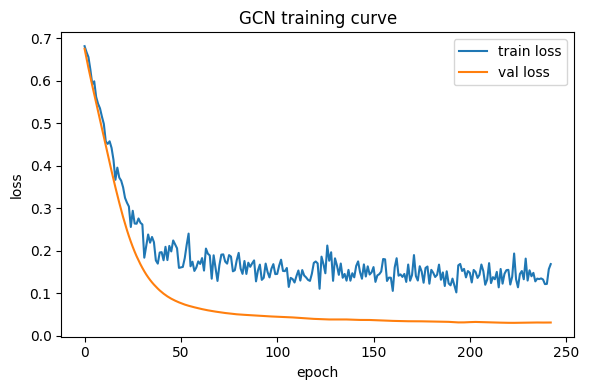

In [13]:
set_seed(0)
gcn_main = GCN(in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=CONFIG["dropout"])
gcn_main, gcn_history = train_model(
    gcn_main, X_t, y_t, A_norm_t, idx_train_t, idx_val_t, CONFIG, class_weights, verbose=True
)
gcn_test_metrics = evaluate(gcn_main, X_t, y_t, A_norm_t, idx_test_t)
print("GCN test metrics:", {k: round(v, 3) for k, v in gcn_test_metrics.items()
                             if k in ("accuracy", "precision", "recall", "f1")})

plt.figure(figsize=(6, 4))
plt.plot(gcn_history["train_loss"], label="train loss")
plt.plot(gcn_history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("GCN training curve")
plt.legend()
plt.tight_layout()
plt.show()


## 10. GCN vs. MLP, averaged over 5 seeds

Same features, same label split, same hidden width — the only difference is whether the
model has access to the normalized adjacency matrix. Averaging over seeds shows whether the
GCN's advantage is reliable or just one lucky run.


In [14]:
def run_seeds(model_class, seeds, A_norm_for_run, **model_kwargs):
    results = []
    for seed in seeds:
        set_seed(seed)
        model = model_class(**model_kwargs)
        model, _ = train_model(model, X_t, y_t, A_norm_for_run, idx_train_t, idx_val_t, CONFIG, class_weights)
        results.append(evaluate(model, X_t, y_t, A_norm_for_run, idx_test_t))
    return results


def summarize(results, name, print_it=True):
    accs = [r["accuracy"] for r in results]
    f1s = [r["f1"] for r in results]
    summary = dict(acc_mean=np.mean(accs), acc_std=np.std(accs),
                    f1_mean=np.mean(f1s), f1_std=np.std(f1s))
    if print_it:
        print(f"{name}: accuracy = {summary['acc_mean']:.3f} +/- {summary['acc_std']:.3f}, "
              f"fraud F1 = {summary['f1_mean']:.3f} +/- {summary['f1_std']:.3f}")
    return summary


gcn_results = run_seeds(GCN, CONFIG["seeds"], A_norm_t,
                         in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=CONFIG["dropout"])
mlp_results = run_seeds(MLP, CONFIG["seeds"], A_norm_t,
                         in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=CONFIG["dropout"])

gcn_summary = summarize(gcn_results, "GCN")
mlp_summary = summarize(mlp_results, "MLP")


GCN: accuracy = 0.980 +/- 0.000, fraud F1 = 0.968 +/- 0.000
MLP: accuracy = 0.920 +/- 0.000, fraud F1 = 0.882 +/- 0.000


## 11. Does removing the graph entirely hurt? (GCN with identity adjacency)

As an extra reference point beyond the MLP: run the *same GCN architecture*, but with the
adjacency replaced by the identity matrix (self-loops only, no neighbor edges at all). This
isolates whether the gap above comes from the extra matrix multiply itself or from actually
aggregating neighbor information.


In [15]:
A_norm_none_t = torch.tensor(normalize_adjacency(np.zeros((N, N), dtype=np.float32)))

nograph_results = run_seeds(GCN, CONFIG["seeds"], A_norm_none_t,
                             in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=CONFIG["dropout"])
nograph_summary = summarize(nograph_results, "GCN, no graph (identity A)")


GCN, no graph (identity A): accuracy = 0.924 +/- 0.008, fraud F1 = 0.888 +/- 0.011


## 12. Edge-corruption ablation sweep

For each corruption level, replace that fraction of edges with random node pairs (same total
edge count, same approximate degree distribution, different topology) and retrain from
scratch, averaged over 5 seeds. If the model is really using structure, accuracy should
degrade as the fraction of randomized edges increases.


corruption=  0%: acc=0.980+/-0.000  F1=0.968+/-0.000
corruption= 25%: acc=0.924+/-0.008  F1=0.876+/-0.020
corruption= 50%: acc=0.904+/-0.056  F1=0.852+/-0.074
corruption= 75%: acc=0.808+/-0.035  F1=0.729+/-0.053
corruption=100%: acc=0.768+/-0.030  F1=0.681+/-0.045


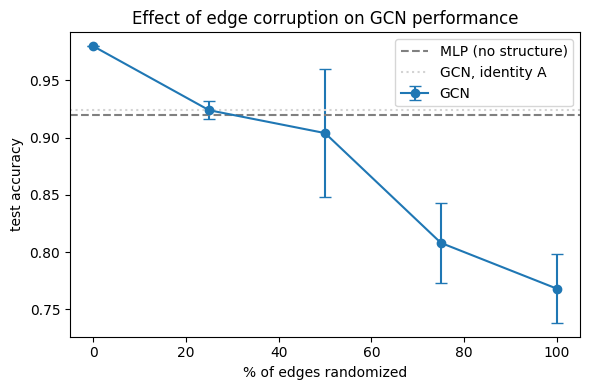

In [16]:
def corrupt_edges(edge_list, n_nodes, frac_random, rng):
    edge_list = edge_list.copy()
    n_edges = len(edge_list)
    n_to_replace = int(round(frac_random * n_edges))
    if n_to_replace == 0:
        return edge_list
    idx_to_replace = rng.choice(n_edges, size=n_to_replace, replace=False)
    existing = set(map(tuple, edge_list))
    new_edges = edge_list.copy()
    for idx in idx_to_replace:
        existing.discard(tuple(edge_list[idx]))
        for _ in range(1000):
            i, j = rng.integers(0, n_nodes, size=2)
            if i != j and (i, j) not in existing and (j, i) not in existing:
                new_edges[idx] = [i, j]
                existing.add((i, j))
                break
    return new_edges


corruption_results = {}
for frac in CONFIG["corruption_levels"]:
    seed_accs, seed_f1s = [], []
    for seed in CONFIG["seeds"]:
        rng = np.random.default_rng(seed)
        corrupted_edges = corrupt_edges(edges, N, frac, rng)
        A_c = build_adjacency(corrupted_edges, N)
        A_norm_c = torch.tensor(normalize_adjacency(A_c))

        set_seed(seed)
        model = GCN(in_dim=X.shape[1], hidden_dim=CONFIG["hidden_dim"], out_dim=2, dropout=CONFIG["dropout"])
        model, _ = train_model(model, X_t, y_t, A_norm_c, idx_train_t, idx_val_t, CONFIG, class_weights)
        m = evaluate(model, X_t, y_t, A_norm_c, idx_test_t)
        seed_accs.append(m["accuracy"])
        seed_f1s.append(m["f1"])

    corruption_results[frac] = dict(
        acc_mean=np.mean(seed_accs), acc_std=np.std(seed_accs),
        f1_mean=np.mean(seed_f1s), f1_std=np.std(seed_f1s),
    )
    r = corruption_results[frac]
    print(f"corruption={frac:>4.0%}: acc={r['acc_mean']:.3f}+/-{r['acc_std']:.3f}  "
          f"F1={r['f1_mean']:.3f}+/-{r['f1_std']:.3f}")

fracs = CONFIG["corruption_levels"]
acc_means = [corruption_results[f]["acc_mean"] for f in fracs]
acc_stds = [corruption_results[f]["acc_std"] for f in fracs]

plt.figure(figsize=(6, 4))
plt.errorbar([f * 100 for f in fracs], acc_means, yerr=acc_stds, marker="o", capsize=4, label="GCN")
plt.axhline(mlp_summary["acc_mean"], color="gray", linestyle="--", label="MLP (no structure)")
plt.axhline(nograph_summary["acc_mean"], color="lightgray", linestyle=":", label="GCN, identity A")
plt.xlabel("% of edges randomized")
plt.ylabel("test accuracy")
plt.title("Effect of edge corruption on GCN performance")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Confusion matrices (GCN vs. MLP, single representative run)

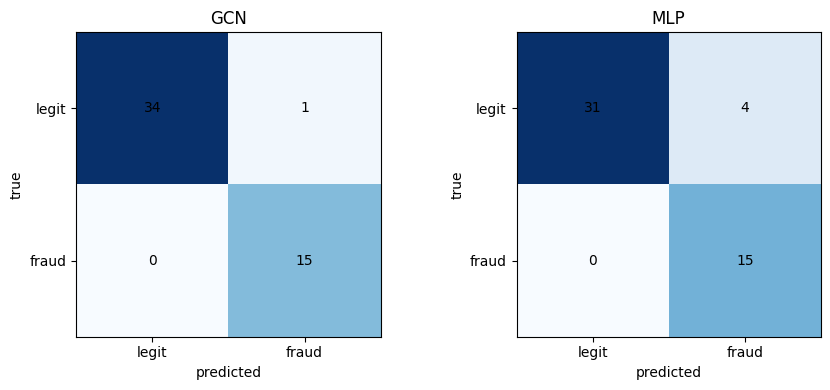

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, metrics) in zip(axes, [("GCN", gcn_test_metrics), ("MLP", mlp_results[0])]):
    cm = confusion_matrix(metrics["y_true"], metrics["preds"])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["legit", "fraud"]); ax.set_yticklabels(["legit", "fraud"])
    for i, j in itertools.product(range(2), range(2)):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()


## 14. Final results table and summary

In [18]:
rows = [
    ["MLP (features only, no structure)", mlp_summary["acc_mean"], mlp_summary["acc_std"],
     mlp_summary["f1_mean"], mlp_summary["f1_std"]],
    ["GCN, identity adjacency (no neighbors)", nograph_summary["acc_mean"], nograph_summary["acc_std"],
     nograph_summary["f1_mean"], nograph_summary["f1_std"]],
]
for frac in CONFIG["corruption_levels"]:
    r = corruption_results[frac]
    label = "GCN, original graph" if frac == 0.0 else f"GCN, {int(frac*100)}% edges randomized"
    rows.append([label, r["acc_mean"], r["acc_std"], r["f1_mean"], r["f1_std"]])

results_df = pd.DataFrame(rows, columns=["Setting", "Test accuracy (mean)", "Test accuracy (std)",
                                          "Test F1 fraud (mean)", "Test F1 fraud (std)"])
results_df


,Setting,Test accuracy (mean),Test accuracy (std),Test F1 fraud (mean),Test F1 fraud (std)
0,"MLP (features only, no structure)",0.920,0.000,0.882,0.000
1,"GCN, identity adjacency (no neighbors)",0.924,0.008,0.888,0.011
2,"GCN, original graph",0.980,0.000,0.968,0.000
3,"GCN, 25% edges randomized",0.924,0.008,0.876,0.020
4,"GCN, 50% edges randomized",0.904,0.056,0.852,0.074
5,"GCN, 75% edges randomized",0.808,0.035,0.729,0.053
6,"GCN, 100% edges randomized",0.768,0.030,0.681,0.045


In [19]:
print("=== Evidence the model uses graph structure ===")
print(f"MLP (features only):              acc={mlp_summary['acc_mean']:.3f}  F1={mlp_summary['f1_mean']:.3f}")
print(f"GCN, identity adjacency:          acc={nograph_summary['acc_mean']:.3f}  F1={nograph_summary['f1_mean']:.3f}")
print(f"GCN, original graph (0% random):  acc={corruption_results[0.0]['acc_mean']:.3f}  "
      f"F1={corruption_results[0.0]['f1_mean']:.3f}")
print(f"GCN, 100% edges randomized:       acc={corruption_results[1.0]['acc_mean']:.3f}  "
      f"F1={corruption_results[1.0]['f1_mean']:.3f}")
print()
print("If the original-graph GCN clearly beats the MLP and the identity-adjacency GCN, and")
print("accuracy degrades monotonically as more edges are randomized, that's direct evidence")
print("the model is relying on the real graph structure rather than features alone.")


=== Evidence the model uses graph structure ===
MLP (features only):              acc=0.920  F1=0.882
GCN, identity adjacency:          acc=0.924  F1=0.888
GCN, original graph (0% random):  acc=0.980  F1=0.968
GCN, 100% edges randomized:       acc=0.768  F1=0.681

If the original-graph GCN clearly beats the MLP and the identity-adjacency GCN, and
accuracy degrades monotonically as more edges are randomized, that's direct evidence
the model is relying on the real graph structure rather than features alone.


## Notes

- `CONFIG` at the top controls every tunable parameter discussed (hidden dim, learning rate,
  dropout, epochs/patience, class weighting, seeds, corruption levels, split ratios). Change
  values there and re-run to sweep.
- The manual verification and permutation checks run on a freshly-initialized, untrained model
  with dropout disabled, so they test the *mechanics* of the layer in isolation from anything
  learned during training.
- All comparisons (GCN vs. MLP, corruption sweep) are averaged over `CONFIG["seeds"]` and report
  mean +/- std, rather than relying on a single run.
